# 01. KOTE 데이터 분석 — 오늘의별일 AI

일기 감정 분석(→ 행성 외형) 모델을 학습하기 전에, 공식 KOTE 데이터셋의 **구조·품질·라벨 분포·텍스트 길이·감정 공존**을 확인하고
학습 입력(44차원 multi-hot)을 점검한다. 이 노트북에서는 모델 학습을 하지 않는다.

**실행 방법**
- VS Code에서 저장소의 `.venv` 커널을 선택하고 *Run All* (저장소 루트·`ai/`·`ai/notebooks/` 어디에서 열어도 경로가 같게 잡힌다).
- 또는 저장소 루트에서 `.venv/Scripts/python ai/scripts/run_notebook.py` → 실행본은 `ai/outputs/kote/`에 저장되고, 이 원본은 출력이 정리된다.

**저장 위치** (모두 Git 제외)
- 원본: `ai/data/raw/kote/` · 가공: `ai/data/processed/kote/` · 상세 결과/그림: `ai/outputs/kote/` · HF 캐시: `ai/.cache/`

**원칙**: 원본과 공식 train/validation/test 분할은 수정하지 않는다. 이 노트북의 화면 출력에는 KOTE 원문을 표시하지 않고, 원문이 필요한 사례는 `ai/outputs/kote/`의 로컬 파일로만 저장한다.

## 1. 환경과 경로 설정

**목적**: 실행 위치와 관계없이 `ai/` 루트를 찾고, **현재 커널에 필요한 패키지가 모두 있는지 먼저 점검**한 뒤, Hugging Face 캐시를 Git 제외 경로(`ai/.cache/`)로 지정한다.
VS Code에서 다른 커널(예: conda 환경)을 고르면 여기서 바로 멈추고 `.venv` 커널을 고르라는 안내가 나온다.
캐시 환경변수는 `huggingface_hub`·`transformers`를 import하기 전에 설정해야 적용된다.
화면에는 개인 경로가 남지 않도록 저장소 기준 상대경로만 출력한다.

In [1]:
import os
import sys
import json
import platform
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 모두 지원)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv가 아닌 커널(예: 다른 conda 환경)이면 필요한 패키지가 없어 중간에 실패한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
P.make_local_dirs()
HF_ENV = configure_hf_cache(P)              # transformers / huggingface_hub import 전에 호출
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

SOURCE_CFG = load_json(P.configs / "kote_source.json")
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
LABEL_CFG = load_json(P.configs / "kote_labels.json")

OUT = P.outputs_kote
FIG_DIR = OUT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def rel(p) -> str:
    return Path(p).resolve().relative_to(P.repo_root).as_posix()


print("Python", platform.python_version(), "|", platform.system(), platform.release())
print("작업 디렉터리 기준 ai 루트 →", rel(AI_ROOT))
for name in ["raw_kote", "processed_kote", "outputs_kote", "checkpoints", "cache"]:
    print(f"  {name:15s} → {rel(getattr(P, name))}")
print("HF_HOME →", rel(HF_ENV["HF_HOME"]))

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
Python 3.13.5 | Windows 11
작업 디렉터리 기준 ai 루트 → ai
  raw_kote        → ai/data/raw/kote
  processed_kote  → ai/data/processed/kote
  outputs_kote    → ai/outputs/kote
  checkpoints     → ai/checkpoints
  cache           → ai/.cache
HF_HOME → ai/.cache/huggingface


그림 저장: ai/outputs/kote/figures/00_font_check.png | 글꼴 누락 없음


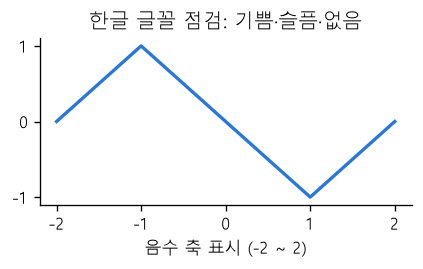

글꼴: Malgun Gothic
{'numpy': '2.5.3', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'pyarrow': '25.0.1', 'transformers': '5.19.0', 'huggingface_hub': '1.33.0'}


In [2]:
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm 위젯 경고(분석과 무관)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

# 한글 글꼴: 설정 파일의 후보 중 설치된 첫 글꼴 사용
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다. 그래프의 한글이 깨질 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False      # 음수 부호 깨짐 방지
plt.rcParams["axes.axisbelow"] = True          # 격자선을 막대 뒤로
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False

def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """jinja2 없이 열별 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
SEQ_COLOR = "#2a78d6"


def save_fig(fig, name):
    """그림 저장 시 글꼴 누락 경고(Glyph missing)를 잡아 한글 표시 여부를 확인한다."""
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(FIG_DIR / name, bbox_inches="tight")
    missing = [str(x.message) for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(FIG_DIR / name)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))


# 한글·음수 축 표시 점검용 그림
fig, ax = plt.subplots(figsize=(4, 1.8))
ax.plot([-2, -1, 0, 1, 2], [0, 1, 0, -1, 0], color=SEQ_COLOR, lw=2)
ax.set_title("한글 글꼴 점검: 기쁨·슬픔·없음")
ax.set_xlabel("음수 축 표시 (-2 ~ 2)")
save_fig(fig, "00_font_check.png")
plt.show()

import pyarrow, transformers, huggingface_hub
print("글꼴:", KOREAN_FONT)
print({m.__name__: m.__version__ for m in [np, pd, matplotlib, pyarrow, transformers, huggingface_hub]})

## 2. KOTE 다운로드 (공식 출처, revision 고정)

**목적**: `ai/configs/kote_source.json`에 고정한 revision으로 공식 파일을 내려받고 SHA-256을 기록한다.

- **GitHub `searle-j/KOTE`**: `train.tsv`, `val.tsv`, `test.tsv` — 공식 분할 그대로 사용
- **Hugging Face `searle-j/kote`**: `raw.json`(평가자별 원시 주석), `kote.py`(라벨 목록 확인용 텍스트, **실행하지 않음**)
- **Hugging Face Parquet 변환본**(`refs/convert/parquet`): TSV 파싱 교차검증용

`datasets.load_dataset("searle-j/kote")`는 원격 로딩 스크립트(`kote.py`) 방식이라 최신 `datasets`에서 지원되지 않는다.
스크립트를 검토한 결과 GitHub TSV를 `csv.DictReader(delimiter="\t")`로 읽는 것이 전부이므로, 같은 TSV를 직접 받아 같은 방식으로 읽는다.

**해석 방법**: `status`가 `reused`이면 기존 다운로드를 SHA-256 검증 후 재사용한 것이다. `raw.json`은 Hugging Face LFS의 SHA-256과 일치해야 한다.

In [3]:
from src.data.kote_download import ensure_kote_raw

manifest = ensure_kote_raw(P.raw_kote, SOURCE_CFG)
manifest_df = pd.DataFrame([
    {
        "file": k,
        "status": manifest["_status"][k],
        "local_path": v["local_path"],
        "revision": v["revision"][:12],
        "sha256": v["sha256"],
        "size_bytes": v["size_bytes"],
        "downloaded_at_utc": v["downloaded_at_utc"],
    }
    for k, v in manifest["files"].items()
])
display(manifest_df)
print("manifest:", rel(P.raw_kote / "manifest.json"))

,file,status,local_path,revision,sha256,size_bytes,downloaded_at_utc
0,github_tsv/train,reused,github/train.tsv,cafd2c3f54a6,62c18dc385f7c140624b693a2806e98060daaf9e7427ceb7d050828d0a55f992,6741184,2026-10-08T05:16:09+00:00
1,github_tsv/validation,reused,github/val.tsv,cafd2c3f54a6,c7d686ee1d63be7f57ec939f372ebdc4ada8eac1c9eeeeac207774976ab69a6e,857808,2026-10-08T05:16:10+00:00
2,github_tsv/test,reused,github/test.tsv,cafd2c3f54a6,8d8e11c5adf374f552cfbe6f2d7b9967e7335cc86c205beeefb6fd8c6ed9deb0,843078,2026-10-08T05:16:10+00:00
3,hf/raw_annotations,reused,hf/raw.json,66f0eefe4b67,eea14dd7e701c39b67ae90cfc897c3f3e77ef64112ca1cd63f779199f492339f,40196880,2026-10-08T05:16:16+00:00
4,hf/loader_script,reused,hf/kote_loader_script.py.txt,66f0eefe4b67,16200e362578b6845f992edcd1924fe2be25e9a2d3fd5625d0fc115342c93f0a,3903,2026-10-08T05:16:17+00:00
5,hf_parquet/train,reused,hf_parquet/train.parquet,81bf41393f7f,8f38510dbd0c262a2ad7cd294b2a7b48684cc1b35e6765e6cac9f285d2a527ff,4747189,2026-10-08T05:16:20+00:00
6,hf_parquet/validation,reused,hf_parquet/validation.parquet,81bf41393f7f,7b43ca44b28e11be8acfb3d5ccecb42be03632a7480acdc8946811f5def72516,606672,2026-10-08T05:16:20+00:00
7,hf_parquet/test,reused,hf_parquet/test.parquet,81bf41393f7f,a2f0d071b7262cf85fc73ef073429934d7ed1c672f8fdf1faf6b0d52d737e6a6,598678,2026-10-08T05:16:21+00:00


manifest: ai/data/raw/kote/manifest.json


**결과 해석**

- 공식 파일 8개(TSV 3, `raw.json`, `kote.py` 텍스트, Parquet 3)를 고정 revision으로 받았고, 파일별 SHA-256·크기·다운로드 시각(UTC)이 `ai/data/raw/kote/manifest.json`에 기록된다.
- `raw.json`의 SHA-256은 Hugging Face LFS에 등록된 값과 일치해야 다운로드가 성공한다(불일치 시 중단).
- 두 번째 실행부터는 모든 파일이 `reused`로 표시된다. 즉 재실행 시 네트워크를 쓰지 않고 SHA-256 검증만 한다.

## 3. (A) 구조와 정답 형식

### 3.1 분할별 행 수·컬럼·타입

**목적**: 공식 로딩 방식(`csv.DictReader`, 탭 구분, 헤더 없음, 필드명 `ID/text/labels`)으로 읽은 결과가 파일의 물리적 줄 수와 맞는지,
필드 수가 어긋난 행이 없는지 확인한다. `labels_raw`는 원본 문자열, `labels`는 정수 리스트로 변환한 값이다.

In [4]:
from src.data.kote_load import (SPLITS, load_kote_splits, load_parquet_splits,
                                load_raw_annotations, count_physical_lines)

dfs = load_kote_splits(P.raw_kote, SOURCE_CFG)

rows = []
for s, df in dfs.items():
    f = P.raw_kote / "github" / SOURCE_CFG["github"]["splits"][s]
    rows.append({
        "split": s,
        "file": f.name,
        "rows_parsed": len(df),
        "physical_lines": count_physical_lines(f),
        "rows_with_extra_fields": df.attrs["rows_with_extra_fields"],
        "rows_with_missing_fields": df.attrs["rows_with_missing_fields"],
        "label_parse_errors": int(df["labels_parse_error"].sum()),
        "columns": ", ".join(df.columns[:3]),
        "py_types": ", ".join(type(df[c].iloc[0]).__name__ for c in ["ID", "text", "labels_raw", "labels"]),
    })
structure_df = pd.DataFrame(rows)
display(structure_df)
print("pandas dtype:", dict(dfs["train"].dtypes.astype(str)))
print("총 댓글 수:", sum(len(d) for d in dfs.values()))

,split,file,rows_parsed,physical_lines,rows_with_extra_fields,rows_with_missing_fields,label_parse_errors,columns,py_types
0,train,train.tsv,40000,40000,0,0,0,"ID, text, labels_raw","str, str, str, list"
1,validation,val.tsv,5000,5000,0,0,0,"ID, text, labels_raw","str, str, str, list"
2,test,test.tsv,5000,5000,0,0,0,"ID, text, labels_raw","str, str, str, list"


pandas dtype: {'ID': 'str', 'text': 'str', 'labels_raw': 'str', 'labels': 'object', 'labels_parse_error': 'bool'}
총 댓글 수: 50000


### 3.2 Hugging Face Parquet 변환본과 교차검증

**목적**: 직접 읽은 TSV가 Hugging Face가 공식 스크립트로 변환한 Parquet와 행 순서·ID·텍스트·라벨까지 같은지 확인한다.

In [5]:
pq_dfs = load_parquet_splits(P.raw_kote)
rows = []
for s in SPLITS:
    a, b = dfs[s], pq_dfs[s]
    same_len = len(a) == len(b)
    rows.append({
        "split": s, "tsv_rows": len(a), "parquet_rows": len(b),
        "same_ID_order": same_len and a["ID"].tolist() == b["ID"].tolist(),
        "same_text": same_len and bool((a["text"].values == b["text"].values).all()),
        "same_labels": same_len and all(x == y for x, y in zip(a["labels"], b["labels"])),
    })
display(pd.DataFrame(rows))

,split,tsv_rows,parquet_rows,same_ID_order,same_text,same_labels
0,train,40000,40000,True,True,True
1,validation,5000,5000,True,True,True
2,test,5000,5000,True,True,True


### 3.3 ID 구조와 중복

**목적**: ID 형식(숫자 문자열 여부, 범위, 선행 0)과 분할 내부·분할 사이 중복을 확인한다.

In [6]:
all_df = pd.concat([d.assign(split=s) for s, d in dfs.items()], ignore_index=True)
ids = all_df["ID"]
is_digit = ids.str.fullmatch(r"\d+")
id_num = pd.to_numeric(ids.where(is_digit), errors="coerce")
id_summary = {
    "total_rows": len(ids),
    "unique_ids": ids.nunique(),
    "all_digit_strings": bool(is_digit.all()),
    "leading_zero_ids": int(ids.str.match(r"0\d").sum()),
    "min_id": int(id_num.min()), "max_id": int(id_num.max()),
    "covers_0_to_max_contiguously": set(id_num.astype(int)) == set(range(int(id_num.max()) + 1)),
}
print(json.dumps(id_summary, ensure_ascii=False, indent=1))

id_sets = {s: set(d["ID"]) for s, d in dfs.items()}
id_dup = pd.DataFrame(
    [{"scope": f"within {s}", "duplicate_rows": int(d["ID"].duplicated().sum())} for s, d in dfs.items()]
    + [{"scope": f"{a} ∩ {b}", "duplicate_rows": len(id_sets[a] & id_sets[b])} for a, b in combinations(SPLITS, 2)]
)
display(id_dup)
# 분할별 ID 범위: 공식 분할이 ID 구간으로 나뉘었는지(무작위 분할인지) 확인
display(all_df.assign(id_num=id_num).groupby("split", sort=False)["id_num"].describe()[["min", "50%", "max"]])

{
 "total_rows": 50000,
 "unique_ids": 50000,
 "all_digit_strings": true,
 "leading_zero_ids": 0,
 "min_id": 0,
 "max_id": 49999,
 "covers_0_to_max_contiguously": true
}


,scope,duplicate_rows
0,within train,0
1,within validation,0
2,within test,0
3,train ∩ validation,0
4,train ∩ test,0
5,validation ∩ test,0


,min,50%,max
split,,,
train,0.0,25025.5,49999.0
validation,7.0,24975.0,49992.0
test,4.0,24804.5,49990.0


### 3.4 라벨 저장 형식과 공식 라벨 ID ↔ 이름 대응

**목적**: `ai/configs/kote_labels.json`(공식 `kote.py`의 `_LABELS`를 실행 없이 `ast`로 파싱해 생성)이
① 로딩 스크립트, ② Parquet 메타데이터의 ClassLabel 이름과 **순서까지** 같은지 확인한다.
라벨 ID는 이 리스트의 인덱스이다. 또한 `labels_raw` 문자열 형식(쉼표 구분 정수, 오름차순 여부)과 관측된 ID 범위를 확인한다.

In [7]:
import pyarrow.parquet as pq
from src.data.labels import parse_labels_from_loader_script, load_label_names

LABELS = load_label_names(P.configs / "kote_labels.json")
NUM_LABELS = len(LABELS)
NONE_ID = LABEL_CFG["none_label"]["id"]
assert LABELS[NONE_ID] == "없음"

script_labels = parse_labels_from_loader_script(
    (P.raw_kote / "hf" / "kote_loader_script.py.txt").read_text(encoding="utf-8"))
hf_meta = json.loads(pq.read_schema(P.raw_kote / "hf_parquet" / "train.parquet").metadata[b"huggingface"])
parquet_labels = hf_meta["info"]["features"]["labels"]["feature"]["names"]

print("라벨 수:", NUM_LABELS, "| 감정 라벨:", NUM_LABELS - 1, "+ '없음'(ID", NONE_ID, ")")
print("config == kote.py _LABELS (순서 포함):", LABELS == script_labels)
print("config == Parquet ClassLabel names  :", LABELS == parquet_labels)
print("라벨 이름 중복:", len(LABELS) - len(set(LABELS)))

lab_raw = all_df["labels_raw"].fillna("")
fmt = pd.Series({
    "형식 '정수(,정수)*' 일치": int(lab_raw.str.fullmatch(r"\d+(,\d+)*").sum()),
    "공백 포함": int(lab_raw.str.contains(r"\s").sum()),
    "오름차순 정렬": int(all_df["labels"].map(lambda x: x is not None and x == sorted(x)).sum()),
    "전체 행": len(all_df),
})
display(fmt.to_frame("rows"))
observed = sorted({v for x in all_df["labels"].dropna() for v in x})
print("관측된 라벨 ID 범위:", observed[0], "~", observed[-1], "| 고유 ID 수:", len(observed))
display(pd.DataFrame({"id": range(NUM_LABELS), "name": LABELS}).set_index("id").T)

라벨 수: 44 | 감정 라벨: 43 + '없음'(ID 24 )
config == kote.py _LABELS (순서 포함): True
config == Parquet ClassLabel names  : True
라벨 이름 중복: 0


,rows
"형식 '정수(,정수)*' 일치",50000
공백 포함,0
오름차순 정렬,50000
전체 행,50000


관측된 라벨 ID 범위: 0 ~ 43 | 고유 ID 수: 44


id,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43
name,불평/불만,환영/호의,감동/감탄,지긋지긋,고마움,슬픔,화남/분노,존경,기대감,우쭐댐/무시함,안타까움/실망,비장함,의심/불신,뿌듯함,편안/쾌적,신기함/관심,아껴주는,부끄러움,공포/무서움,절망,한심함,역겨움/징그러움,짜증,어이없음,없음,패배/자기혐오,귀찮음,힘듦/지침,즐거움/신남,깨달음,죄책감,증오/혐오,흐뭇함(귀여움/예쁨),당황/난처,경악,부담/안_내킴,서러움,재미없음,불쌍함/연민,놀람,행복,불안/걱정,기쁨,안심/신뢰


**결과 해석**

- 행 수는 **train 40,000 / validation 5,000 / test 5,000 (총 50,000)** 으로 공식 안내와 같다. 파싱된 행 수와 물리적 줄 수가 같고, 필드 수가 어긋나거나 라벨 파싱에 실패한 행은 없다.
- 직접 읽은 TSV는 Hugging Face Parquet 변환본과 **행 순서·ID·텍스트·라벨이 모두 같다**. 따라서 로딩 스크립트 없이 TSV를 읽어도 공식 로더와 같은 데이터이다.
- `ID`는 `"0"`~`"49999"`의 숫자 **문자열**이며 전부 고유하고 빈 번호가 없다. 분할 사이에 겹치는 ID가 없고, 세 분할 모두 ID 범위 전체에 퍼져 있어 ID 구간으로 나눈 분할은 아니다(논문: 80/10/10 무작위 분할). 학습 코드에서도 ID는 문자열로 다루는 것이 안전하다.
- `labels`는 공백 없는 쉼표 구분 정수 문자열(`"2,13,15"`)이고 모든 행이 오름차순이다. 관측된 ID는 0–43으로 44개가 모두 등장한다.
- `kote_labels.json`의 44개 라벨은 공식 `kote.py`의 `_LABELS`, Parquet ClassLabel 이름과 **순서까지 같다**. ‘없음’은 ID 24이다. 공식 목록에 없는 라벨(예: ‘긴장’)은 없다.

### 3.5 원시 주석(annotator)과 배포 라벨의 관계

**목적**: `raw.json`의 평가자별 주석을 집계해 **댓글 수**와 **원시 주석 수**를 구분하고,
배포 라벨이 어떤 규칙으로 만들어졌는지 확인한다.

공식 근거(논문 arXiv:2205.05300):
- 4.2절: 댓글 1개당 평가자 5명이 해당 정서를 모두 선택, 5명의 이진 선택을 합해 라벨별 0–5 값
- 4.4절: 댓글별 min-max 스케일링 후 **0.2 초과**이면 1

아래에서는 이 **문서화된 규칙**을 그대로 적용해 배포 라벨과 일치하는지 검증만 한다(다른 규칙을 추정하지 않는다).

In [8]:
from src.data.labels import rater_vote_counts, dichotomize_paper_rule

raw = load_raw_annotations(P.raw_kote)
name_to_id = {n: i for i, n in enumerate(LABELS)}

raw_names = Counter(n for v in raw.values() for names in v["labels"].values() for n in names)
rater_lists = [names for v in raw.values() for names in v["labels"].values()]
raw_summary = {
    "comments_in_raw_json": len(raw),
    "raters_per_comment": dict(Counter(len(v["labels"]) for v in raw.values())),
    "annotations_(comment×rater)": len(rater_lists),
    "label_selections_total": sum(len(x) for x in rater_lists),
    "mean_labels_per_annotation": round(float(np.mean([len(x) for x in rater_lists])), 3),
    "empty_annotations": sum(len(x) == 0 for x in rater_lists),
    "annotations_with_duplicate_label": sum(len(x) != len(set(x)) for x in rater_lists),
    "unknown_label_names": sorted(set(raw_names) - set(LABELS)),
    "annotations_none_with_other_labels": sum(("없음" in x) and len(set(x)) > 1 for x in rater_lists),
    "annotations_none_only": sum(set(x) == {"없음"} for x in rater_lists),
}
print(json.dumps(raw_summary, ensure_ascii=False, indent=1))

# 배포 데이터와 raw.json의 ID·텍스트 대응
ids_rel, ids_raw = set(all_df["ID"]), set(raw)
print("배포 ID ⊂ raw ID:", ids_rel <= ids_raw, "| raw에만 있는 ID:", len(ids_raw - ids_rel))
print("ID별 텍스트 일치:", int((all_df["text"] == all_df["ID"].map(lambda i: raw[i]["text"])).sum()), "/", len(all_df))

{
 "comments_in_raw_json": 50000,
 "raters_per_comment": {
  "5": 50000
 },
 "annotations_(comment×rater)": 250000,
 "label_selections_total": 808735,
 "mean_labels_per_annotation": 3.235,
 "empty_annotations": 0,
 "annotations_with_duplicate_label": 0,
 "unknown_label_names": [],
 "annotations_none_with_other_labels": 99,
 "annotations_none_only": 11821
}
배포 ID ⊂ raw ID: True | raw에만 있는 ID: 0
ID별 텍스트 일치: 50000 / 50000


In [9]:
VOTES = np.stack([rater_vote_counts(raw[i]["labels"], name_to_id, NUM_LABELS) for i in all_df["ID"]])
released_sets = all_df["labels"].map(lambda x: sorted(set(x)))
reproduced = [dichotomize_paper_rule(v, threshold=0.2) for v in VOTES]
match = np.array([a == b for a, b in zip(reproduced, released_sets)])
print(f"논문 규칙(min-max > 0.2) 재현 일치: {match.sum()} / {len(match)}  (불일치 {(~match).sum()})")

# 선택 인원 수(0~5)별로 배포 라벨이 1이 된 비율 — 규칙이 '고정 인원 기준'이 아님을 보여줌
Yrel_tmp = np.zeros_like(VOTES)
for r, labs in enumerate(released_sets):
    Yrel_tmp[r, labs] = 1
vote_tab = pd.DataFrame({"votes": VOTES.ravel(), "released": Yrel_tmp.ravel()})
vote_tab = vote_tab.groupby("votes")["released"].agg(cells="size", positive="sum")
vote_tab["positive_rate"] = (vote_tab["positive"] / vote_tab["cells"]).round(4)
display(vote_tab)
print("댓글별 최대 선택 인원 분포:", {int(k): v for k, v in sorted(Counter(VOTES.max(1)).items())})
print("댓글별 최소 선택 인원 분포:", {int(k): v for k, v in sorted(Counter(VOTES.min(1)).items())})

논문 규칙(min-max > 0.2) 재현 일치: 50000 / 50000  (불일치 0)


,cells,positive,positive_rate
votes,,,
0,1759497,0,0.0000
1,235349,190316,0.8087
2,102045,102045,1.0000
3,57143,57143,1.0000
4,31963,31963,1.0000
5,14003,14003,1.0000


댓글별 최대 선택 인원 분포: {1: 337, 2: 6818, 3: 14195, 4: 16890, 5: 11760}
댓글별 최소 선택 인원 분포: {0: 50000}


**결과 해석**

- **댓글 수와 원시 주석 수는 다르다**: 댓글 50,000개 × 평가자 5명 = 원시 주석 250,000건이고, 라벨 선택은 총 808,735회(주석 1건당 평균 3.235개)이다. 빈 주석, 공식 목록 밖 라벨명, 한 평가자 안 중복 라벨은 없다.
- ‘없음’만 고른 주석은 11,821건이다. ‘없음’과 다른 감정을 함께 고른 주석은 99건으로, 논문의 지침(감정을 찾지 못했을 때만 ‘없음’)과 다르지만 매우 적다.
- 논문 4.4절 규칙(라벨별 선택 인원 0–5 → 댓글별 min-max → **0.2 초과**면 1)을 그대로 적용하면 **배포 라벨 50,000/50,000건이 정확히 재현된다**. 공식 문서에 적힌 규칙이며 데이터로 검증했다.
- 모든 댓글에서 최소 선택 인원이 0이므로 이 규칙은 `선택 인원 / 그 댓글의 최대 선택 인원 > 0.2`와 같다. 최대가 5명인 댓글(11,760개)에서는 2명 이상, 최대가 4명 이하인 댓글에서는 **1명만 골라도** 양성이다. 그래서 1명만 고른 (댓글, 라벨) 칸의 80.87%가 배포 라벨에서 양성이다.
- 결국 배포 라벨은 ‘확실한 감정’이 아니라 **‘가능성이 있는 감정’을 넓게 포함**한다(논문이 밝힌 목적과 같다). 행성 외형처럼 강도가 필요한 용도라면 `raw.json`의 선택 인원(0–5)을 soft label이나 가중치로 쓰는 방안을 검토할 수 있다. 다만 공식 평가는 배포 이진 라벨 기준이다.

## 4. (B) 데이터 품질

### 4.1 텍스트·라벨 결측과 형식 이상

**목적**: 결측·빈 텍스트, 공백만 있는 텍스트, 앞뒤 공백·줄바꿈 포함 여부, 결측·빈 라벨, 범위 밖 라벨 ID, 샘플 안 중복 라벨을 센다.
문제가 있어도 **원본과 공식 분할은 수정하지 않고** 수와 권고만 남긴다.

In [10]:
from src.data.quality import text_flags, label_flags, normalize_minimal

flags = pd.concat([
    all_df[["split", "ID"]],
    text_flags(all_df["text"]),
    label_flags(all_df["labels"], NUM_LABELS),
    all_df[["labels_parse_error"]],
], axis=1)
flag_cols = [c for c in flags.columns if c not in ("split", "ID")]
quality_table = flags.groupby("split", sort=False)[flag_cols].sum().T
quality_table["all"] = quality_table.sum(axis=1)
display(quality_table)

flagged = flags[flags[flag_cols].any(axis=1)]
flagged.to_csv(OUT / "quality_flags_rows.csv", index=False, encoding="utf-8-sig")
print("플래그가 하나라도 있는 행:", len(flagged), "→", rel(OUT / "quality_flags_rows.csv"), "(ID·플래그만 저장)")

split,train,validation,test,all
text_missing,0,0,0,0
text_empty,0,0,0,0
text_whitespace_only,0,0,0,0
text_has_edge_whitespace,597,64,74,735
text_has_newline_or_tab,0,0,0,0
label_missing,0,0,0,0
label_empty,0,0,0,0
label_invalid_id,0,0,0,0
label_duplicate_in_sample,0,0,0,0
labels_parse_error,0,0,0,0


플래그가 하나라도 있는 행: 735 → ai/outputs/kote/quality_flags_rows.csv (ID·플래그만 저장)


### 4.2 ID·텍스트 중복 (분할 내부 / 분할 사이)

**목적**: 텍스트 중복을 **원문 기준**과 **최소 정규화 기준**(앞뒤 공백 제거 + 연속 공백을 하나로)으로 나눠 센다.
분할 사이 중복은 평가 누수(leakage) 가능성을, 같은 텍스트의 라벨 불일치는 주석 일관성을 보여준다.

- `dup_groups`: 2회 이상 등장하는 고유 텍스트 수 · `rows_in_groups`: 그 그룹에 속한 행 수 · `extra_rows`: 첫 등장 외 추가 행 수

In [11]:
all_df["text_norm"] = all_df["text"].map(normalize_minimal)


def dup_stats(df: pd.DataFrame, key: str) -> list[dict]:
    out = []
    for s, g in df.groupby("split", sort=False):
        vc = g[key].value_counts()
        out.append({"key": key, "scope": f"within {s}", "dup_groups": int((vc > 1).sum()),
                    "rows_in_groups": int(g[key].duplicated(keep=False).sum()),
                    "extra_rows": int(g[key].duplicated().sum())})
    sets = {s: set(g[key]) for s, g in df.groupby("split")}
    for a, b in combinations(SPLITS, 2):
        inter = sets[a] & sets[b]
        out.append({"key": key, "scope": f"{a} ∩ {b}", "dup_groups": len(inter),
                    "rows_in_groups": int(df[df["split"].isin([a, b]) & df[key].isin(inter)].shape[0]),
                    "extra_rows": None})
    vc = df[key].value_counts()
    out.append({"key": key, "scope": "전체(분할 무시)", "dup_groups": int((vc > 1).sum()),
                "rows_in_groups": int(df[key].duplicated(keep=False).sum()),
                "extra_rows": int(df[key].duplicated().sum())})
    return out


dup_table = pd.DataFrame(dup_stats(all_df, "text") + dup_stats(all_df, "text_norm"))
display(dup_table)

# 정규화 기준 중복 그룹의 라벨 일치 여부
all_df["label_key"] = all_df["labels"].map(lambda x: ",".join(map(str, sorted(set(x)))))
dup_rows = all_df[all_df["text_norm"].duplicated(keep=False)].copy()
grp = dup_rows.groupby("text_norm")
grp_info = pd.DataFrame({
    "rows": grp.size(),
    "n_splits": grp["split"].nunique(),
    "n_label_sets": grp["label_key"].nunique(),
    "raw_text_variants": grp["text"].nunique(),
})
print("정규화 기준 중복 그룹:", len(grp_info),
      "| 라벨 집합이 서로 다른 그룹:", int((grp_info["n_label_sets"] > 1).sum()),
      "| 분할을 넘는 그룹:", int((grp_info["n_splits"] > 1).sum()),
      "| 정규화 후에만 중복인 그룹:", int((grp_info["raw_text_variants"] > 1).sum()))
print("그룹 크기 분포:", dict(sorted(Counter(grp_info["rows"]).items())))

# 원문 포함 상세는 로컬 outputs에만 저장
dup_rows["group_id"] = dup_rows.groupby("text_norm").ngroup()
dup_rows.sort_values(["group_id", "split"])[["group_id", "split", "ID", "labels_raw", "text"]].to_csv(
    OUT / "quality_duplicates_text_norm_detail.csv", index=False, encoding="utf-8-sig")
dup_table.to_csv(OUT / "quality_duplicates_summary.csv", index=False, encoding="utf-8-sig")
print("상세(원문 포함, 로컬 전용):", rel(OUT / "quality_duplicates_text_norm_detail.csv"))

,key,scope,dup_groups,rows_in_groups,extra_rows
0,text,within train,0,0,0.0
1,text,within validation,0,0,0.0
2,text,within test,0,0,0.0
3,text,train ∩ validation,0,0,NaN
4,text,train ∩ test,0,0,NaN
5,text,validation ∩ test,0,0,NaN
6,text,전체(분할 무시),0,0,0.0
7,text_norm,within train,0,0,0.0
8,text_norm,within validation,0,0,0.0
9,text_norm,within test,0,0,0.0


정규화 기준 중복 그룹: 1 | 라벨 집합이 서로 다른 그룹: 1 | 분할을 넘는 그룹: 1 | 정규화 후에만 중복인 그룹: 1
그룹 크기 분포: {2: 1}
상세(원문 포함, 로컬 전용): ai/outputs/kote/quality_duplicates_text_norm_detail.csv


In [12]:
# 짧은 텍스트: 중복의 주요 원인인지 확인 (원문은 표시하지 않음)
char_len_all = all_df["text"].str.len()
dup_mask = all_df["text_norm"].duplicated(keep=False)
display(pd.DataFrame({
    "중복 행": char_len_all[dup_mask].describe()[["count", "mean", "50%", "max"]],
    "비중복 행": char_len_all[~dup_mask].describe()[["count", "mean", "50%", "max"]],
}).round(1))

,중복 행,비중복 행
count,2.0,49998.0
mean,46.5,57.3
50%,46.5,42.0
max,47.0,404.0


**결과 해석**

- 결측·빈 텍스트, 공백만 있는 텍스트, 줄바꿈·탭이 든 텍스트는 **0건**이다. 앞뒤 공백이 있는 텍스트는 **735건**(train 597 / validation 64 / test 74)이며, 토크나이저가 공백을 무시하므로 학습에 미치는 영향은 작다.
- 라벨 결측, 빈 라벨, 범위 밖 ID, 샘플 안 중복 라벨, 파싱 오류는 모두 **0건**이다.
- **원문 기준** 텍스트 중복은 분할 내부·분할 사이 모두 0건이다. **최소 정규화 기준**으로는 1그룹(2행)이 train↔validation 사이에서 겹친다(ID 36258 ↔ 37217). 공백 1개만 다르고, 라벨은 16개 vs 6개(Jaccard 0.375)로 크게 다르다. 같은 문장이라도 평가자 묶음에 따라 라벨이 크게 달라질 수 있음을 보여 준다.
- 관측된 최소 길이가 10자이다. 공식 문서에서 길이 필터 기준을 찾지 못했으므로 원인을 단정하지 않는다.
- **처리 권고**: 공식 분할과 원본은 그대로 둔다. 겹치는 1쌍은 validation 5,000건 중 1건이라 평가 영향이 미미하므로 제거하지 않고 기록만 한다(`quality_duplicates_text_norm_detail.csv`). 앞뒤 공백은 모델 입력 단계에서만 정리한다.

## 5. (C) 감정 라벨 분포

**목적**: 분할별 라벨 빈도·양성 비율, 샘플당 라벨 수, 빈발·희소 감정, 분할 간 비율 차이, ‘없음’의 동시 등장을 본다.

**해석 시 주의**: KOTE는 **다중 라벨**이므로 한 댓글이 여러 라벨에 동시에 양성이다.
라벨별 양성 비율(= 그 라벨이 붙은 댓글 수 / 댓글 수)을 모두 더하면 100%를 넘으며, 그 합은 샘플당 평균 라벨 수와 같다.

In [13]:
from src.data.labels import to_multihot

Y = {s: to_multihot(dfs[s]["labels"].tolist(), NUM_LABELS) for s in SPLITS}
N = {s: len(dfs[s]) for s in SPLITS}

dist = pd.DataFrame({"label_id": range(NUM_LABELS), "label": LABELS})
for s in SPLITS:
    dist[f"count_{s}"] = Y[s].sum(0).astype(int)
    dist[f"rate_{s}"] = dist[f"count_{s}"] / N[s]
dist["count_all"] = sum(dist[f"count_{s}"] for s in SPLITS)
dist["rate_all"] = dist["count_all"] / sum(N.values())
dist.to_csv(OUT / "label_distribution.csv", index=False, encoding="utf-8-sig")

for s in SPLITS:
    print(f"{s:10s} 양성 비율 합 = {dist[f'rate_{s}'].sum():.3f}  (= 샘플당 평균 라벨 수 {Y[s].sum(1).mean():.3f})")

show = dist.sort_values("rate_train", ascending=False)[
    ["label_id", "label", "count_train", "rate_train", "rate_validation", "rate_test"]]
show_fmt(show, {c: "{:.2%}" for c in show.columns if c.startswith("rate")}, index=False)

train      양성 비율 합 = 7.911  (= 샘플당 평균 라벨 수 7.911)
validation 양성 비율 합 = 7.872  (= 샘플당 평균 라벨 수 7.872)
test       양성 비율 합 = 7.930  (= 샘플당 평균 라벨 수 7.930)


,label_id,label,count_train,rate_train,rate_validation,rate_test
0,10,안타까움/실망,17465,43.66%,44.76%,43.70%
1,0,불평/불만,16696,41.74%,42.88%,42.26%
2,23,어이없음,15996,39.99%,41.22%,41.10%
3,22,짜증,14930,37.33%,37.44%,38.18%
4,6,화남/분노,12299,30.75%,31.38%,30.76%
5,20,한심함,12201,30.50%,29.94%,30.38%
6,12,의심/불신,11565,28.91%,29.58%,30.78%
7,8,기대감,11197,27.99%,27.74%,27.18%
8,28,즐거움/신남,10867,27.17%,25.46%,26.42%
9,2,감동/감탄,10778,26.95%,25.86%,26.46%


그림 저장: ai/outputs/kote/figures/01_label_rate_by_split.png | 글꼴 누락 없음


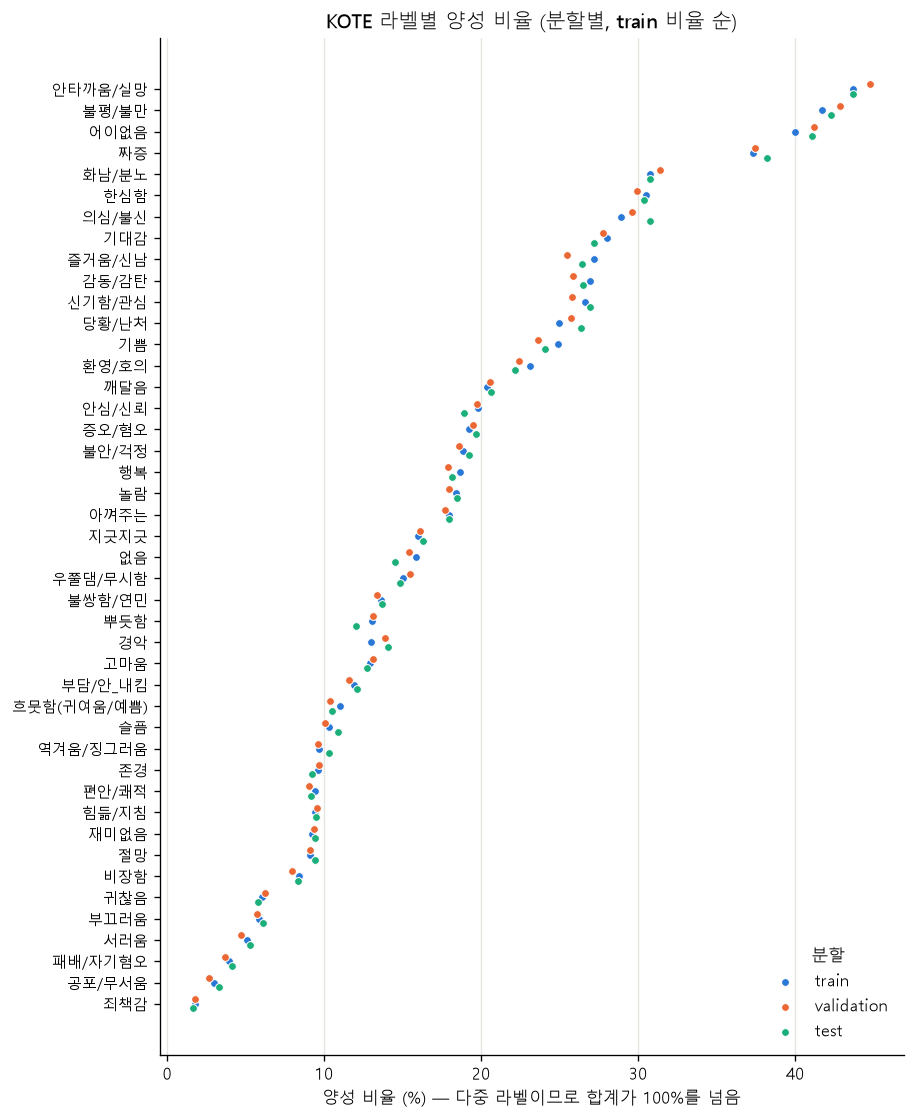

In [14]:
order = dist.sort_values("rate_train")["label"].tolist()
fig, ax = plt.subplots(figsize=(8, 11))
ypos = np.arange(len(order))
offsets = {"train": 0.0, "validation": 0.22, "test": -0.22}
for s in SPLITS:
    r = dist.set_index("label").loc[order, f"rate_{s}"] * 100
    ax.scatter(r, ypos + offsets[s], s=22, color=SPLIT_COLORS[s], label=s, zorder=3, edgecolor="white", linewidth=0.6)
ax.set_yticks(ypos, order, fontsize=9)
ax.set_xlabel("양성 비율 (%) — 다중 라벨이므로 합계가 100%를 넘음")
ax.set_title("KOTE 라벨별 양성 비율 (분할별, train 비율 순)")
ax.grid(axis="x", color="#e4e4e0", lw=0.8)
ax.legend(title="분할", loc="lower right", frameon=False)
save_fig(fig, "01_label_rate_by_split.png")
plt.show()

,count,mean,std,min,25%,50%,75%,max
train,40000.0,7.91,3.10,1.0,6.0,8.0,10.0,22.0
validation,5000.0,7.87,3.06,1.0,6.0,8.0,10.0,21.0
test,5000.0,7.93,3.07,1.0,6.0,8.0,10.0,19.0


그림 저장: ai/outputs/kote/figures/02_labels_per_sample.png | 글꼴 누락 없음


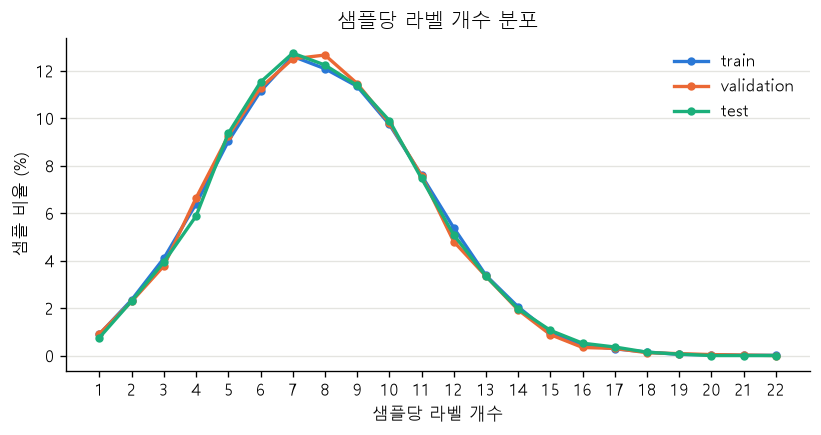

In [15]:
# 샘플당 라벨 개수
k_counts = pd.DataFrame({s: pd.Series(Y[s].sum(1).astype(int)).value_counts(normalize=True).sort_index()
                         for s in SPLITS}).fillna(0)
k_stats = pd.DataFrame({s: pd.Series(Y[s].sum(1)).describe() for s in SPLITS}).T.round(2)
display(k_stats)
k_counts.to_csv(OUT / "labels_per_sample.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 3.6))
for s in SPLITS:
    ax.plot(k_counts.index, k_counts[s] * 100, marker="o", ms=4, lw=2, color=SPLIT_COLORS[s], label=s)
ax.set_xlabel("샘플당 라벨 개수")
ax.set_ylabel("샘플 비율 (%)")
ax.set_title("샘플당 라벨 개수 분포")
ax.set_xticks(k_counts.index)
ax.grid(axis="y", color="#e4e4e0", lw=0.8)
ax.legend(frameon=False)
save_fig(fig, "02_labels_per_sample.png")
plt.show()

In [16]:
# 빈발·희소 감정 (train 기준) 및 분할 간 비율 차이
rare_thr = ANALYSIS_CFG["rare_label_positive_rate"]
print("train 상위 10개:", ", ".join(f"{r.label}({r.rate_train:.1%})" for r in dist.nlargest(10, "rate_train").itertuples()))
print("train 하위 10개:", ", ".join(f"{r.label}({r.rate_train:.1%})" for r in dist.nsmallest(10, "rate_train").itertuples()))
rare = dist[dist["rate_train"] < rare_thr]
print(f"train 양성 비율 < {rare_thr:.0%} 라벨: {len(rare)}개", list(rare["label"]))
print("train 최소 양성 수:", int(dist["count_train"].min()), f"({dist.loc[dist['count_train'].idxmin(), 'label']})",
      "| validation 최소:", int(dist["count_validation"].min()), "| test 최소:", int(dist["count_test"].min()))
print("최대/최소 양성 비율 배수(train):", round(dist["rate_train"].max() / dist["rate_train"].min(), 1))

diff = pd.DataFrame({"label": LABELS})
for s in ("validation", "test"):
    diff[f"{s}-train (%p)"] = (dist[f"rate_{s}"] - dist["rate_train"]) * 100
    diff[f"{s}/train"] = dist[f"rate_{s}"] / dist["rate_train"]
diff.to_csv(OUT / "label_rate_split_diff.csv", index=False, encoding="utf-8-sig")
summary_diff = pd.DataFrame({
    s: {"max |Δ| (%p)": diff[f"{s}-train (%p)"].abs().max(),
        "label at max |Δ|": diff.loc[diff[f"{s}-train (%p)"].abs().idxmax(), "label"],
        "mean |Δ| (%p)": diff[f"{s}-train (%p)"].abs().mean(),
        "ratio range": f"{diff[f'{s}/train'].min():.2f}–{diff[f'{s}/train'].max():.2f}"}
    for s in ("validation", "test")})
display(summary_diff)

train 상위 10개: 안타까움/실망(43.7%), 불평/불만(41.7%), 어이없음(40.0%), 짜증(37.3%), 화남/분노(30.7%), 한심함(30.5%), 의심/불신(28.9%), 기대감(28.0%), 즐거움/신남(27.2%), 감동/감탄(26.9%)
train 하위 10개: 죄책감(1.7%), 공포/무서움(3.0%), 패배/자기혐오(4.0%), 서러움(5.1%), 부끄러움(5.8%), 귀찮음(6.1%), 비장함(8.4%), 절망(9.1%), 재미없음(9.2%), 힘듦/지침(9.4%)
train 양성 비율 < 1% 라벨: 0개 []
train 최소 양성 수: 698 (죄책감) | validation 최소: 89 | test 최소: 84
최대/최소 양성 비율 배수(train): 25.0


,validation,test
max |Δ| (%p),1.7075,1.8675
label at max |Δ|,즐거움/신남,의심/불신
mean |Δ| (%p),0.46642,0.487557
ratio range,0.90–1.07,0.91–1.10


In [17]:
# '없음'(NO EMOTION)과 다른 라벨의 동시 등장
rows = []
for s in SPLITS:
    has_none = Y[s][:, NONE_ID] == 1
    k = Y[s].sum(1)
    rows.append({"split": s, "with_없음": int(has_none.sum()), "rate": has_none.mean(),
                 "없음_only": int((has_none & (k == 1)).sum()),
                 "없음+others": int((has_none & (k > 1)).sum()),
                 "mean_labels_when_없음": float(k[has_none].mean()) if has_none.any() else np.nan})
none_df = pd.DataFrame(rows)
show_fmt(none_df, {"rate": "{:.2%}", "mean_labels_when_없음": "{:.2f}"}, index=False)

Yall = np.vstack([Y[s] for s in SPLITS])
mask = Yall[:, NONE_ID] == 1
co = pd.Series(Yall[mask].sum(0), index=LABELS).drop("없음").sort_values(ascending=False)
print("‘없음’과 함께 가장 자주 붙는 라벨(전체, 상위 8):",
      ", ".join(f"{k}({int(v)}, {v / mask.sum():.0%})" for k, v in co.head(8).items()))

,split,with_없음,rate,없음_only,없음+others,mean_labels_when_없음
0,train,6344,15.86%,83,6261,7.45
1,validation,769,15.38%,6,763,7.26
2,test,725,14.50%,12,713,7.52


‘없음’과 함께 가장 자주 붙는 라벨(전체, 상위 8): 기대감(2669, 34%), 안타까움/실망(2581, 33%), 신기함/관심(2492, 32%), 깨달음(2486, 32%), 어이없음(2243, 29%), 의심/불신(1853, 24%), 불평/불만(1798, 23%), 즐거움/신남(1703, 22%)


**결과 해석**

- 샘플당 평균 라벨 수는 **7.91 / 7.87 / 7.93**(train/validation/test)으로 논문 값(7.91)과 같다. 중앙값은 8개, 범위는 1–22개이다. 다중 라벨이므로 라벨별 양성 비율의 합은 이 평균과 같아 100%를 크게 넘는다(약 791%).
- 빈발 라벨은 안타까움/실망(43.7%), 불평/불만(41.7%), 어이없음(40.0%), 짜증(37.3%), 화남/분노(30.7%) 순이다. 온라인 댓글이라 비판·부정 계열이 상위에 많다.
- 희소 라벨은 죄책감(1.7%, train 698건), 공포/무서움(3.0%), 패배/자기혐오(4.0%), 서러움(5.1%), 부끄러움(5.8%) 순이다. 양성 비율 1% 미만인 라벨은 없지만 최대/최소 비율 차이가 약 25배이다. validation·test에서는 죄책감 양성이 각각 89건, 84건뿐이라 이 라벨의 평가 지표는 변동이 클 수 있다.
- 분할 간 차이는 작다. train 대비 라벨별 양성 비율 차이는 최대 1.71%p(validation, 즐거움/신남), 1.87%p(test, 의심/불신)이고 평균 약 0.5%p이며, 비율 배수는 0.90–1.10이다. 공식 분할을 그대로 써도 분포 차이로 인한 문제는 크지 않다.
- **‘없음’은 단독 라벨이 아니다**: ‘없음’이 붙은 샘플은 train 15.9%이고, 그중 98.7%(6,261/6,344)가 다른 감정과 함께 붙는다. ‘없음’만 붙은 샘플은 train 83건뿐이다. 1–2명만 ‘없음’을 골라도 양성이 되는 집계 규칙 때문이다. 따라서 ‘없음’을 상호배타적인 중립 클래스로 쓰면 안 되고, 44개 독립 출력 중 하나로 다뤄야 한다. 빈 라벨([]) 샘플은 0건이다.

## 6. (D) 텍스트 길이

**목적**: 문자 수와 토큰 수 분포(평균·중앙값·90/95/99 백분위수·최댓값)를 구하고, 최대 길이 128/256/512 토큰에서 잘리는 샘플 수를 센다.

토크나이저는 `beomi/KcELECTRA-base`의 **토크나이저 파일만** 받는다(가중치 `*.bin/*.safetensors` 제외).
기본 revision은 KOTE 공식 코드가 사용하는 `v2021`이며, 특수 토큰(`[CLS]`, `[SEP]`)을 포함하고 truncation 없이 측정한다.
`main` revision(2023 BBPE)은 특수 토큰을 자동으로 붙이지 않아 이번 기준과 맞지 않으므로 제외했다(`analysis.json` 참고).
`v2022`(WordPiece)는 비교용으로 함께 측정한다. 토크나이저를 받지 못하면 문자 분석만 완료하고 토큰 분석은 **미완료**로 표시한다.

In [18]:
pcts = ANALYSIS_CFG["percentiles"]


def length_stats(series_by_split: dict) -> pd.DataFrame:
    out = {}
    for s, v in series_by_split.items():
        v = pd.Series(v)
        q = v.quantile(pcts)
        out[s] = {"mean": v.mean(), "median": v.median(),
                  **{f"p{int(p * 100)}": q[p] for p in pcts if p != 0.5}, "max": v.max(), "min": v.min()}
    return pd.DataFrame(out).T.round(1)


all_df["char_len"] = all_df["text"].str.len()
char_by_split = {s: all_df.loc[all_df["split"] == s, "char_len"] for s in SPLITS}
char_by_split["all"] = all_df["char_len"]
char_stats = length_stats(char_by_split)
display(char_stats)
char_stats.to_csv(OUT / "length_stats_chars.csv", encoding="utf-8-sig")

,mean,median,p90,p95,p99,max,min
train,57.2,42.0,115.0,139.0,237.0,404.0,10.0
validation,58.4,43.0,118.0,140.0,231.0,402.0,10.0
test,57.3,42.0,115.0,143.0,240.0,397.0,10.0
all,57.3,42.0,115.0,139.0,237.0,404.0,10.0


In [19]:
from src.data.tokenizer_utils import download_tokenizer_files, load_tokenizer, token_lengths

TOK_CFG = ANALYSIS_CFG["tokenizer"]
TOKEN_STATUS = {}
TOKENIZERS = {}
for rev_name, rev in [(TOK_CFG["revision_name"], TOK_CFG["revision"]), *TOK_CFG["compare_revisions"].items()]:
    try:
        tok_dir = download_tokenizer_files(TOK_CFG["repo_id"], rev, TOK_CFG["allow_patterns"])
        tok = load_tokenizer(tok_dir)
        all_df[f"tok_len_{rev_name}"] = token_lengths(tok, all_df["text"].tolist())
        TOKENIZERS[rev_name] = tok
        TOKEN_STATUS[rev_name] = "완료"
    except Exception as e:  # 네트워크 등 실패 시 문자 분석은 유지
        TOKEN_STATUS[rev_name] = f"미완료: {type(e).__name__}: {str(e)[:200]}"
print("토큰 분석 상태:", TOKEN_STATUS)

PRIMARY = TOK_CFG["revision_name"]
if PRIMARY in TOKENIZERS:
    tok = TOKENIZERS[PRIMARY]
    demo = tok("오늘은 정말 기분이 좋았다 ㅎㅎ", add_special_tokens=True, truncation=False)  # KOTE 원문이 아닌 예시 문장
    print(f"[{PRIMARY}] 예시 토큰:", tok.convert_ids_to_tokens(demo["input_ids"]))
    # 실제 데이터 일부에서 특수 토큰 위치 점검
    enc = tok(all_df["text"].iloc[:500].tolist(), add_special_tokens=True, truncation=False)["input_ids"]
    print("앞 500개 샘플: 첫 토큰=[CLS]", all(x[0] == tok.cls_token_id for x in enc),
          "| 끝 토큰=[SEP]", all(x[-1] == tok.sep_token_id for x in enc),
          "| [UNK] 포함 샘플 비율", round(np.mean([tok.unk_token_id in x for x in enc]), 3))

토큰 분석 상태: {'v2021': '완료', 'v2022': '완료'}
[v2021] 예시 토큰: ['[CLS]', '오늘은', '정말', '기분이', '좋았', '##다', 'ㅎㅎ', '[SEP]']
앞 500개 샘플: 첫 토큰=[CLS] True | 끝 토큰=[SEP] True | [UNK] 포함 샘플 비율 0.002


In [20]:
trunc_rows, tok_stats = [], {}
for rev_name, status in TOKEN_STATUS.items():
    if status != "완료":
        continue
    col = f"tok_len_{rev_name}"
    by_split = {s: all_df.loc[all_df["split"] == s, col] for s in SPLITS}
    by_split["all"] = all_df[col]
    tok_stats[rev_name] = length_stats(by_split)
    for s, v in by_split.items():
        for L in ANALYSIS_CFG["length_thresholds"]:
            trunc_rows.append({"tokenizer": rev_name, "split": s, "max_len": L,
                               "truncated": int((v > L).sum()), "rate": (v > L).mean()})
if tok_stats:
    tok_stats_df = pd.concat(tok_stats, names=["tokenizer", "split"])
    display(tok_stats_df)
    tok_stats_df.to_csv(OUT / "length_stats_tokens.csv", encoding="utf-8-sig")
    trunc_df = pd.DataFrame(trunc_rows)
    trunc_df.to_csv(OUT / "truncation_by_max_len.csv", index=False, encoding="utf-8-sig")
    print("[잘리는 샘플 수: 토큰 수 > max_len]")
    display(trunc_df.pivot_table(index=["tokenizer", "split"], columns="max_len", values="truncated").astype(int))
    print("[잘리는 샘플 비율]")
    rate_pv = trunc_df.pivot_table(index=["tokenizer", "split"], columns="max_len", values="rate")
    show_fmt(rate_pv, {c: "{:.3%}" for c in rate_pv.columns})
    if f"tok_len_{PRIMARY}" in all_df:
        p = all_df[f"tok_len_{PRIMARY}"]
        print(f"[{PRIMARY}] 문자/토큰 비율 중앙값: {(all_df['char_len'] / (p - 2).clip(lower=1)).median():.2f} 문자/토큰")
        for L in (64, 96, 128, 160, 192, 256):
            print(f"  ≤{L:3d} 토큰 포함 비율: {(p <= L).mean():.3%}")
    else:
        print(f"기본 토크나이저({PRIMARY}) 분석 미완료 — 위 TOKEN_STATUS 참고")
else:
    print("토큰 분석 미완료 — 위 TOKEN_STATUS 참고")

mean  median   p90   p95    p99    max  min
tokenizer split                                                  
v2021     train       27.8    21.0  53.0  65.0  108.0  237.0  3.0
          validation  28.4    22.0  54.0  66.0  105.0  182.0  4.0
          test        27.9    21.0  53.0  66.0  107.0  211.0  3.0
          all         27.9    21.0  53.0  65.0  108.0  237.0  3.0
v2022     train       27.1    21.0  51.0  63.0  105.0  233.0  3.0
          validation  27.6    21.0  52.0  63.0  101.0  181.0  4.0
          test        27.2    21.0  52.0  64.1  103.0  208.0  3.0
          all         27.1    21.0  51.0  63.0  104.0  233.0  3.0

[잘리는 샘플 수: 토큰 수 > max_len]


max_len               128  256  512
tokenizer split                    
v2021     all         172    0    0
          test         15    0    0
          train       144    0    0
          validation   13    0    0
v2022     all         146    0    0
          test         13    0    0
          train       121    0    0
          validation   12    0    0

[잘리는 샘플 비율]


max_len                  128     256     512
tokenizer split                             
v2021     all         0.344%  0.000%  0.000%
          test        0.300%  0.000%  0.000%
          train       0.360%  0.000%  0.000%
          validation  0.260%  0.000%  0.000%
v2022     all         0.292%  0.000%  0.000%
          test        0.260%  0.000%  0.000%
          train       0.302%  0.000%  0.000%
          validation  0.240%  0.000%  0.000%

[v2021] 문자/토큰 비율 중앙값: 2.22 문자/토큰
  ≤ 64 토큰 포함 비율: 94.824%
  ≤ 96 토큰 포함 비율: 98.366%
  ≤128 토큰 포함 비율: 99.656%
  ≤160 토큰 포함 비율: 99.906%
  ≤192 토큰 포함 비율: 99.988%
  ≤256 토큰 포함 비율: 100.000%


그림 저장: ai/outputs/kote/figures/03_length_hist.png | 글꼴 누락 없음


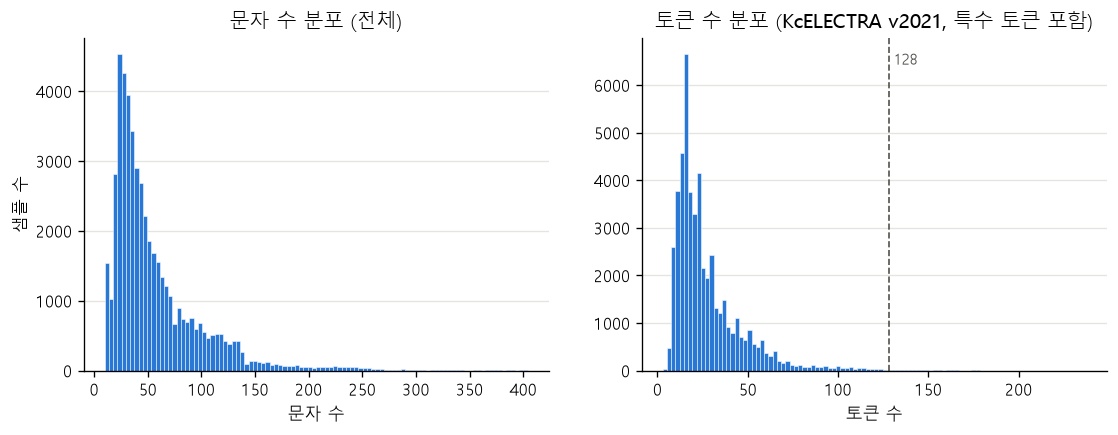

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.hist(all_df["char_len"], bins=100, color=SEQ_COLOR, edgecolor="white", linewidth=0.3)
ax.set_title("문자 수 분포 (전체)")
ax.set_xlabel("문자 수")
ax.set_ylabel("샘플 수")
ax = axes[1]
if f"tok_len_{PRIMARY}" in all_df:
    v = all_df[f"tok_len_{PRIMARY}"]
    ax.hist(v, bins=100, color=SEQ_COLOR, edgecolor="white", linewidth=0.3)
    for L in ANALYSIS_CFG["length_thresholds"]:
        if L <= v.max() * 1.05:
            ax.axvline(L, color="#52514e", ls="--", lw=1)
            ax.text(L, ax.get_ylim()[1] * 0.92, f" {L}", color="#52514e", fontsize=9)
    ax.set_title(f"토큰 수 분포 (KcELECTRA {PRIMARY}, 특수 토큰 포함)")
    ax.set_xlabel("토큰 수")
else:
    ax.text(0.5, 0.5, "토큰 분석 미완료", ha="center", va="center", transform=ax.transAxes)
for a in axes:
    a.grid(axis="y", color="#e4e4e0", lw=0.8)
save_fig(fig, "03_length_hist.png")
plt.show()

**결과 해석**

- 문자 수: 평균 57.3, 중앙값 42, p90 115, p95 139, p99 237, 최대 404, 최소 10.
- 토큰 수(KcELECTRA **v2021**, `[CLS]`·`[SEP]` 포함, truncation 없음): 평균 27.9, 중앙값 21, p90 53, p95 65, p99 108, **최대 237**. 문자/토큰 비율 중앙값은 약 2.2이다.
- 잘리는 샘플: **128토큰 172건(0.344%)**(train 144 / validation 13 / test 15), **256·512토큰 0건**. 논문의 ‘512를 넘는 입력 없음’ 서술과 맞는다. v2022 토크나이저는 조금 더 짧게 나뉜다(128 초과 146건, 최대 233).
- 앞 500개 샘플에서 모든 인코딩이 `[CLS]`로 시작하고 `[SEP]`으로 끝나며, `[UNK]`가 든 샘플은 0.2%였다.
- **첫 학습 권장**: `max_length=256` + 동적 패딩(배치 안 최장 길이까지만 패딩). 잘리는 샘플이 0건이고, 중앙값이 21토큰이라 동적 패딩이면 실제 연산량은 128과 거의 같다. 고정 패딩이 필요하면 128(0.34% 잘림)도 가능하다. 512는 이 데이터에서는 이득이 없다.
- **주의**: KOTE는 짧은 댓글이다. 실제 서비스 일기는 더 길 가능성이 높으므로, 추론 단계의 길이 정책(512 사용 또는 문장 단위 분할 후 집계)은 일기 길이 분포를 따로 확인한 뒤 정해야 한다.

## 7. (E) 감정 공존

**목적**: train 분할에서 두 라벨이 같은 댓글에 함께 붙는 빈도를 본다.

- **원시 공동 출현 수** `n(A∩B)`: 빈발 라벨끼리 자연히 커지므로 ‘관련성’과 같지 않다.
- **정규화 지표**: Jaccard `n(A∩B) / n(A∪B)`, 조건부 확률 `P(B|A)`, lift `P(A∩B) / (P(A)P(B))`(1보다 크면 우연보다 자주 함께 등장).
- 표본이 적은 쌍은 지표가 불안정하므로 정규화 지표 순위는 `n(A∩B) ≥ min_pair_count`(설정값)인 쌍만 사용한다.

In [22]:
MIN_PAIR = ANALYSIS_CFG["cooccurrence"]["min_pair_count"]
TOP_K = ANALYSIS_CFG["cooccurrence"]["top_k"]
Ytr = Y["train"].astype(np.int64)
Ntr = len(Ytr)
C = Ytr.T @ Ytr
n = np.diag(C)

pairs = []
for i, j in combinations(range(NUM_LABELS), 2):
    c = int(C[i, j])
    pairs.append({"label_a": LABELS[i], "label_b": LABELS[j], "n_a": int(n[i]), "n_b": int(n[j]), "n_ab": c,
                  "jaccard": c / (n[i] + n[j] - c) if (n[i] + n[j] - c) else np.nan,
                  "p_b_given_a": c / n[i], "p_a_given_b": c / n[j],
                  "lift": c * Ntr / (n[i] * n[j])})
pairs = pd.DataFrame(pairs)
pairs["enough_support"] = pairs["n_ab"] >= MIN_PAIR
pairs.to_csv(OUT / "cooccurrence_pairs_train.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(C, index=LABELS, columns=LABELS).to_csv(OUT / "cooccurrence_matrix_train.csv", encoding="utf-8-sig")

print(f"쌍 {len(pairs)}개 중 n_ab ≥ {MIN_PAIR}: {int(pairs['enough_support'].sum())}개 | n_ab = 0: {int((pairs['n_ab'] == 0).sum())}개")
fmt = {"jaccard": "{:.3f}", "p_b_given_a": "{:.2f}", "p_a_given_b": "{:.2f}", "lift": "{:.2f}"}
print("\n[원시 공동 출현 수 상위]")
show_fmt(pairs.nlargest(TOP_K // 2, "n_ab"), fmt, index=False)
print(f"\n[Jaccard 상위, n_ab ≥ {MIN_PAIR}]")
show_fmt(pairs[pairs["enough_support"]].nlargest(TOP_K // 2, "jaccard"), fmt, index=False)
print(f"\n[lift 상위, n_ab ≥ {MIN_PAIR}]")
show_fmt(pairs[pairs["enough_support"]].nlargest(TOP_K // 2, "lift"), fmt, index=False)
print(f"\n[lift 하위(함께 잘 안 나옴), n_a, n_b ≥ 1000]")
show_fmt(pairs[(pairs["n_a"] >= 1000) & (pairs["n_b"] >= 1000)].nsmallest(8, "lift"), fmt, index=False)

쌍 946개 중 n_ab ≥ 100: 891개 | n_ab = 0: 0개

[원시 공동 출현 수 상위]


,label_a,label_b,n_a,n_b,n_ab,jaccard,p_b_given_a,p_a_given_b,lift,enough_support
0,불평/불만,짜증,16696,14930,12822,0.682,0.77,0.86,2.06,True
1,불평/불만,안타까움/실망,16696,17465,11797,0.527,0.71,0.68,1.62,True
2,불평/불만,어이없음,16696,15996,11319,0.530,0.68,0.71,1.70,True
3,짜증,어이없음,14930,15996,10785,0.535,0.72,0.67,1.81,True
4,불평/불만,화남/분노,16696,12299,10666,0.582,0.64,0.87,2.08,True
5,화남/분노,짜증,12299,14930,10446,0.622,0.85,0.70,2.28,True
6,안타까움/실망,어이없음,17465,15996,10335,0.447,0.59,0.65,1.48,True
7,안타까움/실망,짜증,17465,14930,10112,0.454,0.58,0.68,1.55,True
8,한심함,어이없음,12201,15996,9549,0.512,0.78,0.60,1.96,True
9,화남/분노,어이없음,12299,15996,8971,0.464,0.73,0.56,1.82,True



[Jaccard 상위, n_ab ≥ 100]


,label_a,label_b,n_a,n_b,n_ab,jaccard,p_b_given_a,p_a_given_b,lift,enough_support
0,불평/불만,짜증,16696,14930,12822,0.682,0.77,0.86,2.06,True
1,화남/분노,짜증,12299,14930,10446,0.622,0.85,0.70,2.28,True
2,행복,기쁨,7473,9967,6468,0.590,0.87,0.65,3.47,True
3,불평/불만,화남/분노,16696,12299,10666,0.582,0.64,0.87,2.08,True
4,즐거움/신남,기쁨,10867,9967,7523,0.565,0.69,0.75,2.78,True
5,짜증,어이없음,14930,15996,10785,0.535,0.72,0.67,1.81,True
6,불평/불만,어이없음,16696,15996,11319,0.530,0.68,0.71,1.70,True
7,불평/불만,안타까움/실망,16696,17465,11797,0.527,0.71,0.68,1.62,True
8,한심함,어이없음,12201,15996,9549,0.512,0.78,0.60,1.96,True
9,화남/분노,증오/혐오,12299,7684,6395,0.471,0.52,0.83,2.71,True



[lift 상위, n_ab ≥ 100]


,label_a,label_b,n_a,n_b,n_ab,jaccard,p_b_given_a,p_a_given_b,lift,enough_support
0,패배/자기혐오,죄책감,1581,698,237,0.116,0.15,0.34,8.59,True
1,패배/자기혐오,서러움,1581,2031,499,0.160,0.32,0.25,6.22,True
2,부끄러움,죄책감,2329,698,236,0.085,0.10,0.34,5.81,True
3,슬픔,서러움,4137,2031,1188,0.239,0.29,0.58,5.66,True
4,힘듦/지침,서러움,3769,2031,927,0.190,0.25,0.46,4.84,True
5,절망,서러움,3652,2031,846,0.175,0.23,0.42,4.56,True
6,절망,패배/자기혐오,3652,1581,642,0.140,0.18,0.41,4.45,True
7,슬픔,죄책감,4137,698,320,0.071,0.08,0.46,4.43,True
8,슬픔,절망,4137,3652,1652,0.269,0.40,0.45,4.37,True
9,죄책감,서러움,698,2031,152,0.059,0.22,0.07,4.29,True



[lift 하위(함께 잘 안 나옴), n_a, n_b ≥ 1000]


,label_a,label_b,n_a,n_b,n_ab,jaccard,p_b_given_a,p_a_given_b,lift,enough_support
0,화남/분노,행복,12299,7473,160,0.008,0.01,0.02,0.07,True
1,증오/혐오,행복,7684,7473,101,0.007,0.01,0.01,0.07,True
2,편안/쾌적,증오/혐오,3771,7684,55,0.005,0.01,0.01,0.08,False
3,역겨움/징그러움,행복,3864,7473,57,0.005,0.01,0.01,0.08,False
4,고마움,역겨움/징그러움,5181,3864,40,0.004,0.01,0.01,0.08,False
5,증오/혐오,흐뭇함(귀여움/예쁨),7684,4401,68,0.006,0.01,0.02,0.08,False
6,화남/분노,편안/쾌적,12299,3771,98,0.006,0.01,0.03,0.08,False
7,화남/분노,흐뭇함(귀여움/예쁨),12299,4401,117,0.007,0.01,0.03,0.09,True


그림 저장: ai/outputs/kote/figures/04_cooccurrence_jaccard_train.png | 글꼴 누락 없음


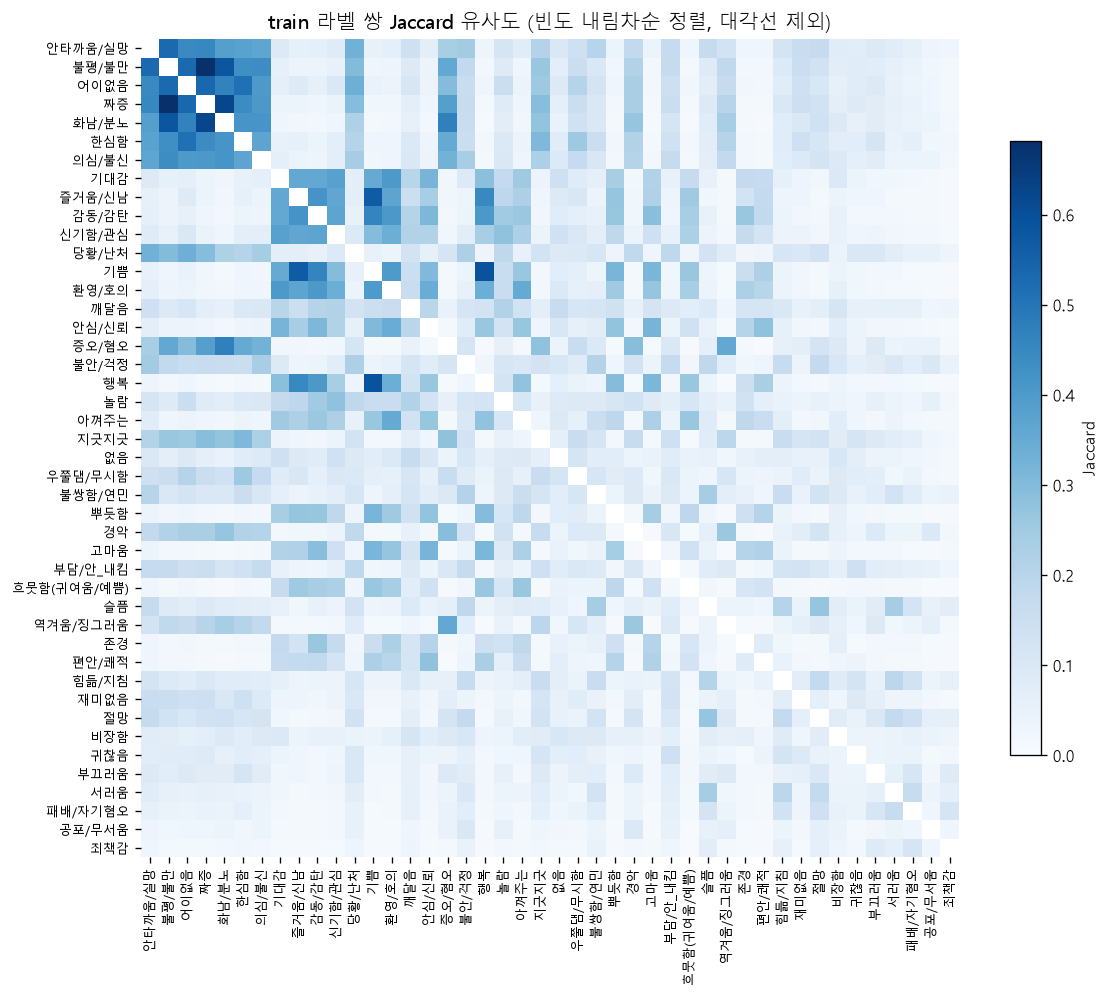

In [23]:
freq_order = np.argsort(-n)
J = np.zeros((NUM_LABELS, NUM_LABELS))
for i in range(NUM_LABELS):
    for j in range(NUM_LABELS):
        if i != j:
            u = n[i] + n[j] - C[i, j]
            J[i, j] = C[i, j] / u if u else np.nan
J_ord = J[np.ix_(freq_order, freq_order)]
np.fill_diagonal(J_ord, np.nan)
names_ord = [LABELS[i] for i in freq_order]

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(J_ord, cmap="Blues", vmin=0, vmax=np.nanmax(J_ord))
ax.set_xticks(range(NUM_LABELS), names_ord, rotation=90, fontsize=7.5)
ax.set_yticks(range(NUM_LABELS), names_ord, fontsize=7.5)
ax.set_title("train 라벨 쌍 Jaccard 유사도 (빈도 내림차순 정렬, 대각선 제외)")
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Jaccard")
save_fig(fig, "04_cooccurrence_jaccard_train.png")
plt.show()

**결과 해석**

- 44개 라벨의 946쌍 모두 train에서 한 번 이상 함께 등장하고, 891쌍은 공동 출현이 100건 이상이다. 샘플당 라벨이 약 8개이기 때문이다.
- **원시 공동 출현 수** 상위는 불평/불만–짜증(12,822), 불평/불만–안타까움/실망, 불평/불만–어이없음처럼 빈발 부정 라벨끼리의 쌍이다. 빈도가 높은 라벨끼리는 자연히 수가 커지므로 이 순위만으로 ‘관련이 깊다’고 해석하면 안 된다.
- **Jaccard** 상위: 불평/불만–짜증 0.68, 화남/분노–짜증 0.62, 행복–기쁨 0.59, 불평/불만–화남/분노 0.58, 즐거움/신남–기쁨 0.57. 의미가 가까운 라벨이 강하게 겹친다.
- **lift** 상위(공동 출현 100건 이상)에는 희소한 슬픔·자기비난 계열이 모인다: 패배/자기혐오–죄책감 8.6(237건), 패배/자기혐오–서러움 6.2, 부끄러움–죄책감 5.8, 슬픔–서러움 5.7. 희소 라벨은 lift가 크게 나오기 쉬우므로 순위보다는 ‘묶음’ 정도로 해석한다.
- lift가 가장 낮은 쌍은 화남/분노–행복, 증오/혐오–행복(0.07)으로, 반대 극성 감정은 거의 함께 붙지 않는다.
- 히트맵에서 비판·부정 블록(안타까움/실망·불평/불만·어이없음·짜증·화남/분노·한심함·의심/불신·증오/혐오)과 긍정 블록(기대감·즐거움/신남·감동/감탄·신기함/관심·기쁨·환영/호의·행복·안심/신뢰 등)이 뚜렷하다. 44개 라벨 사이에 중복 정보가 많다는 뜻이며, 행성 외형 매핑에서 감정 군집을 쓸 근거가 된다. 다만 공존 수치는 넓게 포함하는 집계 규칙(1명 선택도 양성)의 영향을 받으므로 인과·의미 관계로 단정하지 않는다.

## 8. (F) 전처리 판단

**목적**: 웃음(ㅋㅋ·ㅎㅎ), 울음(ㅠㅠ·ㅜㅜ), 그림 이모지와 ♥·☆ 같은 기호, ASCII 이모티콘, 반복 문장부호, URL, HTML 태그 형태(꺾쇠 제목 표기도 걸림)·HTML 엔티티, 제어/폭 0 문자, 별표·동그라미 연속(마스킹 또는 강조) 등의 빈도를 센다.
이런 표현 중 상당수는 **감정 단서**일 수 있으므로 삭제 여부를 정하기 전에, 해당 표현이 있는 댓글에서 어떤 라벨이 상대적으로 더 자주 붙는지(비율 배수)도 확인한다.
원문은 수정하지 않으며, 패턴별 사례(원문 포함)는 로컬 `outputs`에만 저장한다.

In [24]:
from src.data.quality import TEXT_PATTERNS, pattern_flags

pf = pattern_flags(all_df["text"])
pat_rates = pd.concat([pf.groupby(all_df["split"]).mean().T, pf.sum().rename("count_all")], axis=1)[[*SPLITS, "count_all"]]
show_fmt(pat_rates, {s: "{:.2%}" for s in SPLITS})
pat_rates.to_csv(OUT / "text_pattern_rates.csv", encoding="utf-8-sig")

# 패턴별 사례(원문 포함) — 로컬 전용
examples = []
for name in TEXT_PATTERNS:
    hit = all_df.loc[pf[name], ["split", "ID", "text"]].head(5)
    examples += [{"pattern": name, **r} for r in hit.to_dict("records")]
pd.DataFrame(examples).to_csv(OUT / "text_pattern_examples.csv", index=False, encoding="utf-8-sig")
print("패턴 사례(원문 포함, 로컬 전용):", rel(OUT / "text_pattern_examples.csv"))

,train,validation,test,count_all
laugh_ㅋㅎ,14.99%,15.08%,14.80%,7488
cry_ㅠㅜ,5.57%,5.02%,5.78%,2767
jamo_any,27.07%,26.74%,27.66%,13548
emoji_pictograph,0.00%,0.00%,0.00%,1
symbol_heart_star,0.06%,0.08%,0.00%,26
emoticon_ascii,4.47%,4.94%,4.30%,2251
repeated_punct,19.57%,20.48%,19.56%,9829
ellipsis_char,0.01%,0.00%,0.00%,2
url,0.01%,0.02%,0.02%,7
angle_bracket_tag_like,0.01%,0.02%,0.00%,4


패턴 사례(원문 포함, 로컬 전용): ai/outputs/kote/text_pattern_examples.csv


In [25]:
# 패턴 유무에 따른 라벨 양성 비율 배수 (train)
tr_mask = (all_df["split"] == "train").values
base_rate = Ytr.mean(0)
rows = []
for name in ["laugh_ㅋㅎ", "cry_ㅠㅜ", "emoji_pictograph", "symbol_heart_star", "emoticon_ascii",
             "repeated_punct", "url", "html_entity", "asterisk_or_circle_run"]:
    m = pf.loc[tr_mask, name].values
    if m.sum() < 30:
        rows.append({"pattern": name, "n_train": int(m.sum()), "top_labels (rate ratio)": "표본 30 미만 — 해석 보류"})
        continue
    rate = Ytr[m].mean(0)
    ratio = np.where(base_rate > 0, rate / base_rate, np.nan)
    ok = Ytr[m].sum(0) >= 20
    top = [k for k in np.argsort(-np.nan_to_num(ratio)) if ok[k]][:5]
    rows.append({"pattern": name, "n_train": int(m.sum()),
                 "top_labels (rate ratio)": ", ".join(f"{LABELS[k]}×{ratio[k]:.1f}" for k in top)})
pattern_label_df = pd.DataFrame(rows)
show_fmt(pattern_label_df, {}, index=False)
pattern_label_df.to_csv(OUT / "text_pattern_label_ratio_train.csv", index=False, encoding="utf-8-sig")

,pattern,n_train,top_labels (rate ratio)
0,laugh_ㅋㅎ,5994,"즐거움/신남×2.4, 흐뭇함(귀여움/예쁨)×1.9, 우쭐댐/무시함×1.8, 기쁨×1.7, 신기함/관심×1.6"
1,cry_ㅠㅜ,2227,"슬픔×4.3, 서러움×3.3, 죄책감×2.3, 절망×2.1, 불쌍함/연민×1.9"
2,emoji_pictograph,1,표본 30 미만 — 해석 보류
3,symbol_heart_star,22,표본 30 미만 — 해석 보류
4,emoticon_ascii,1789,"고마움×2.6, 행복×2.4, 편안/쾌적×2.2, 기쁨×2.1, 뿌듯함×2.0"
5,repeated_punct,7827,"서러움×1.5, 죄책감×1.4, 힘듦/지침×1.4, 슬픔×1.4, 패배/자기혐오×1.4"
6,url,5,표본 30 미만 — 해석 보류
7,html_entity,2,표본 30 미만 — 해석 보류
8,asterisk_or_circle_run,37,"화남/분노×1.8, 불평/불만×1.4"


**결과 해석**

- 감정 단서가 되는 표현이 흔하다: 웃음 자모 반복(ㅋㅋ·ㅎㅎ) 15.0%, 울음(ㅠㅠ·ㅜㅜ) 5.6%, 반복 문장부호 19.6%, ASCII 이모티콘 4.5%, 자음·모음 단독 문자 포함 27.1%.
- 이 표현들은 라벨과 뚜렷하게 연관된다(train, 해당 표현이 있을 때 라벨 양성 비율 / 전체 비율): ㅋㅋ → 즐거움/신남 ×2.4, ㅠㅠ → 슬픔 ×4.3·서러움 ×3.3, 이모티콘 → 고마움 ×2.6·행복 ×2.4. **삭제하면 감정 정보가 사라지므로 보존한다.**
- 드문 패턴: 그림 이모지 1건, ♥·☆ 등 기호 26건, URL 7건, HTML 엔티티 4건(`&quot;` 등), HTML 태그 형태 4건(확인해 보니 대부분 `<제목>` 같은 꺾쇠 표기로 실제 HTML이 아님), 제어문자 1건, 별표·동그라미 연속 46건(마스킹과 강조가 섞임). 표본이 30건 미만인 패턴은 라벨 연관을 해석하지 않았다.
- **권장 전처리(모델 입력 단계에서만 적용, 원문은 보존)**:
  1. 앞뒤 공백 제거·연속 공백 축소(최소 정규화)
  2. HTML 엔티티 복원(`html.unescape`): 4건
  3. 제어문자·폭 0 문자는 공백으로 치환: 1건
  4. ㅋㅋ·ㅠㅠ·이모티콘·이모지·♥·반복 문장부호·꺾쇠 표기는 **유지**. 긴 반복을 줄이는 정규화는 토크나이저 분절과 성능을 비교한 뒤에만 도입
  5. URL은 7건뿐이라 그대로 둔다(일기 데이터에서 많아지면 그때 치환 토큰 검토)

## 9. (G) 학습 입력 준비 점검 — 44차원 float32 multi-hot

**목적**: `src/data/labels.py::to_multihot`가 공식 라벨 순서(`kote_labels.json`)대로 정확히 변환하는지 실제 데이터로 점검한다.

- 차원(N×44)과 dtype(float32)
- 열 순서 = 공식 라벨 ID 순서
- 행별 양성 수 = 원본의 **고유** 라벨 개수, 전체 양성 수 일치
- 벡터 → 라벨 ID 역변환이 원본과 일치, 텍스트–벡터 대응(같은 행 위치, raw.json의 ID별 텍스트와 대조)
- **빈 라벨([])과 ‘없음’은 다르다**: 빈 라벨은 0벡터, ‘없음’은 ID 24 위치만 1. 라벨 결측(None)·범위 밖 ID는 오류로 중단한다.

In [26]:
check_rows = []
for s in SPLITS:
    y, df = Y[s], dfs[s]
    uniq = df["labels"].map(lambda x: sorted(set(x)))
    col_counts = Counter(v for x in uniq for v in x)
    check_rows.append({
        "split": s, "shape": y.shape, "dtype": str(y.dtype),
        "rows_match_df": y.shape[0] == len(df),
        "dim_is_44": y.shape[1] == NUM_LABELS == 44,
        "row_sum == n_unique_labels": bool((y.sum(1) == uniq.map(len).values).all()),
        "total_positives_match": int(y.sum()) == int(uniq.map(len).sum()),
        "column_order_counts_match": all(int(y[:, j].sum()) == col_counts.get(j, 0) for j in range(NUM_LABELS)),
        "inverse_equals_original": all(np.flatnonzero(y[r]).tolist() == uniq.iloc[r] for r in range(len(df))),
        "only_0_or_1": bool(np.isin(y, (0.0, 1.0)).all()),
        "zero_vectors": int((y.sum(1) == 0).sum()),
    })
display(pd.DataFrame(check_rows).set_index("split").T)

# 텍스트–벡터 대응: 행 i의 ID로 raw.json(독립 출처)의 텍스트를 찾아 같은 행 텍스트와 비교
for s in SPLITS:
    df = dfs[s]
    ok = (df["text"].values == np.array([raw[i]["text"] for i in df["ID"]])).all()
    print(f"{s:10s} 행 순서 기준 ID–텍스트–벡터 대응 일치: {bool(ok)}")

# 예시(원문 없이 ID와 라벨명만)
rng = np.random.default_rng(0)
for r in rng.choice(N["train"], 3, replace=False):
    print(f"ID={dfs['train']['ID'].iloc[r]} labels_raw={dfs['train']['labels_raw'].iloc[r]} → 벡터 양성 라벨:",
          [LABELS[k] for k in np.flatnonzero(Y["train"][r])])

split,train,validation,test
shape,"(40000, 44)","(5000, 44)","(5000, 44)"
dtype,float32,float32,float32
rows_match_df,True,True,True
dim_is_44,True,True,True
row_sum == n_unique_labels,True,True,True
total_positives_match,True,True,True
column_order_counts_match,True,True,True
inverse_equals_original,True,True,True
only_0_or_1,True,True,True
zero_vectors,0,0,0


train      행 순서 기준 ID–텍스트–벡터 대응 일치: True
validation 행 순서 기준 ID–텍스트–벡터 대응 일치: True
test       행 순서 기준 ID–텍스트–벡터 대응 일치: True
ID=14425 labels_raw=1,2,15,23,24,28,40,42 → 벡터 양성 라벨: ['환영/호의', '감동/감탄', '신기함/관심', '어이없음', '없음', '즐거움/신남', '행복', '기쁨']
ID=18254 labels_raw=1,2,9,15,16,23,29,34,39,43 → 벡터 양성 라벨: ['환영/호의', '감동/감탄', '우쭐댐/무시함', '신기함/관심', '아껴주는', '어이없음', '깨달음', '경악', '놀람', '안심/신뢰']
ID=16709 labels_raw=1,2,7,8,15,35,39,43 → 벡터 양성 라벨: ['환영/호의', '감동/감탄', '존경', '기대감', '신기함/관심', '부담/안_내킴', '놀람', '안심/신뢰']


In [27]:
# 빈 라벨 vs '없음' vs 결측/범위 밖 (합성 입력으로 동작 확인)
demo = to_multihot([[], [NONE_ID], [0, 0, 5]], NUM_LABELS)
print("빈 라벨 []        → 양성 수", int(demo[0].sum()))
print("['없음'] (ID 24)   → 양성 위치", np.flatnonzero(demo[1]).tolist(), LABELS[NONE_ID])
print("[0, 0, 5] (중복)   → 양성 위치", np.flatnonzero(demo[2]).tolist(), "(중복은 1로 합쳐짐)")
print("빈 라벨과 '없음'이 같은 벡터인가:", bool((demo[0] == demo[1]).all()))
for bad in ([None], [[44]], [[-1]]):
    try:
        to_multihot(bad, NUM_LABELS)
        print(bad, "→ 오류 없음 (예상과 다름)")
    except ValueError as e:
        print(bad, "→ ValueError:", e)

빈 라벨 []        → 양성 수 0
['없음'] (ID 24)   → 양성 위치 [24] 없음
[0, 0, 5] (중복)   → 양성 위치 [0, 5] (중복은 1로 합쳐짐)
빈 라벨과 '없음'이 같은 벡터인가: False
[None] → ValueError: 0번째 샘플의 라벨이 결측입니다.
[[44]] → ValueError: 0번째 샘플에 범위 밖 라벨 ID 44가 있습니다.
[[-1]] → ValueError: 0번째 샘플에 범위 밖 라벨 ID -1가 있습니다.


In [28]:
# 가공 결과 저장 (원본은 그대로 두고 processed/에 별도 저장)
P.processed_kote.mkdir(parents=True, exist_ok=True)
for s in SPLITS:
    out = dfs[s][["ID", "text", "labels"]].copy()
    out["labels"] = out["labels"].map(lambda x: sorted(set(x)))
    out["num_labels"] = out["labels"].map(len)
    out.to_parquet(P.processed_kote / f"{s}.parquet", index=False)
    np.save(P.processed_kote / f"{s}_multihot.npy", Y[s])
proc_meta = {
    "label_order": LABELS, "none_label_id": NONE_ID, "dtype": "float32",
    "row_order": "공식 TSV 행 순서 그대로 (parquet 행 i == npy 행 i)",
    "labels_column": "샘플 안 중복 제거·오름차순 정렬한 라벨 ID 리스트",
    "source_sha256": {k: v["sha256"] for k, v in manifest["files"].items() if k.startswith("github_tsv")},
    "rows": N,
}
(P.processed_kote / "meta.json").write_text(json.dumps(proc_meta, ensure_ascii=False, indent=2), encoding="utf-8")
for f in sorted(P.processed_kote.iterdir()):
    print(f"{rel(f):55s} {f.stat().st_size / 1e6:7.2f} MB")

ai/data/processed/kote/meta.json                           0.00 MB
ai/data/processed/kote/test.parquet                        0.58 MB
ai/data/processed/kote/test_multihot.npy                   0.88 MB
ai/data/processed/kote/train.parquet                       4.61 MB
ai/data/processed/kote/train_multihot.npy                  7.04 MB
ai/data/processed/kote/validation.parquet                  0.59 MB
ai/data/processed/kote/validation_multihot.npy             0.88 MB


**결과 해석**

- 세 분할 모두 **(N, 44) float32**이고 값은 0/1뿐이다. 열 순서는 공식 라벨 ID 순서이며, 열별 양성 수가 원본 라벨 집계와 같다.
- 행별 양성 수는 원본의 고유 라벨 수와 같고, 벡터를 라벨 ID로 되돌리면 모든 행이 원본과 같다. 0벡터(빈 라벨)는 0건이다.
- 행 i의 ID로 독립 출처인 `raw.json`의 텍스트를 찾으면 같은 행의 텍스트와 모두 일치한다. 즉 텍스트–ID–벡터 대응이 맞다.
- 빈 라벨 `[]`은 0벡터, ‘없음’은 ID 24만 1인 벡터로 **서로 다르다**. 결측(None)과 범위 밖 ID는 `ValueError`로 중단하므로 조용히 0벡터가 되지 않는다.
- 가공 결과(`ai/data/processed/kote/`): 분할별 `*.parquet`(ID, text, labels, num_labels)와 `*_multihot.npy`의 행 순서는 공식 TSV와 같다. `meta.json`에 라벨 순서와 원본 SHA-256이 들어 있다.

## 10. 요약 수치 저장

**목적**: 보고서(`ai/reports/kote_analysis_ko.md`) 작성에 쓰는 **집계 수치만** `ai/outputs/kote/summary.json`으로 저장한다(원문 없음).

In [29]:
def _py(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


summary = {
    "rows": N, "total_rows": sum(N.values()),
    "num_labels": NUM_LABELS, "none_label_id": NONE_ID,
    "id_summary": id_summary,
    "raw_annotations": raw_summary,
    "paper_rule_match": {"matched": int(match.sum()), "total": int(len(match))},
    "quality_table": quality_table.to_dict(),
    "duplicates": dup_table.to_dict("records"),
    "dup_groups_norm": {"groups": int(len(grp_info)), "label_conflict": int((grp_info["n_label_sets"] > 1).sum()),
                        "cross_split": int((grp_info["n_splits"] > 1).sum())},
    "labels_per_sample": k_stats.to_dict(),
    "label_rate_sum": {s: float(dist[f"rate_{s}"].sum()) for s in SPLITS},
    "top10_train": dist.nlargest(10, "rate_train")[["label", "count_train", "rate_train"]].to_dict("records"),
    "bottom10_train": dist.nsmallest(10, "rate_train")[["label", "count_train", "rate_train"]].to_dict("records"),
    "split_diff": summary_diff.to_dict(),
    "none_label": none_df.to_dict("records"),
    "char_stats": char_stats.to_dict(),
    "token_status": TOKEN_STATUS,
    "token_stats": {k: v.to_dict() for k, v in tok_stats.items()},
    "truncation": trunc_rows,
    "pattern_rates": pat_rates.to_dict(),
    "pattern_label_ratio": pattern_label_df.to_dict("records"),
    "cooc_top_count": pairs.nlargest(10, "n_ab")[["label_a", "label_b", "n_ab", "jaccard", "lift"]].to_dict("records"),
    "cooc_top_jaccard": pairs[pairs["enough_support"]].nlargest(10, "jaccard")[["label_a", "label_b", "n_ab", "jaccard", "lift"]].to_dict("records"),
    "cooc_top_lift": pairs[pairs["enough_support"]].nlargest(10, "lift")[["label_a", "label_b", "n_ab", "jaccard", "lift"]].to_dict("records"),
    "multihot_checks": pd.DataFrame(check_rows).astype(str).to_dict("records"),
}
(OUT / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=1, default=_py), encoding="utf-8")
print("저장:", rel(OUT / "summary.json"))
print("outputs 파일:", sorted(p.name for p in OUT.iterdir()))

저장: ai/outputs/kote/summary.json
outputs 파일: ['01_data_analysis.executed.ipynb', 'cooccurrence_matrix_train.csv', 'cooccurrence_pairs_train.csv', 'figures', 'label_distribution.csv', 'label_rate_split_diff.csv', 'labels_per_sample.csv', 'length_stats_chars.csv', 'length_stats_tokens.csv', 'quality_duplicates_summary.csv', 'quality_duplicates_text_norm_detail.csv', 'quality_flags_rows.csv', 'summary.json', 'text_pattern_examples.csv', 'text_pattern_label_ratio_train.csv', 'text_pattern_rates.csv', 'truncation_by_max_len.csv']


## 11. 결론과 다음 단계

**데이터 상태**
- 공식 KOTE: 50,000건(40,000/5,000/5,000), 44개 라벨(감정 43 + ‘없음’). 구조·형식 이상, 결측, 잘못된 라벨은 없다.
- 배포 라벨은 5명의 원시 주석을 논문 4.4절 규칙으로 이진화한 것이며, 50,000건 모두 재현된다. 1명만 골라도 양성이 되는 경우가 많아 샘플당 약 7.9개 라벨이 붙는 **관대한 라벨**이다.
- 품질 이슈는 작다: 앞뒤 공백 735건, 분할 사이 정규화 중복 1쌍(공백 1개 차이, 라벨 불일치). 원본과 분할은 수정하지 않았다.

**학습 준비 판단**
- 입력 길이: `max_length=256` + 동적 패딩(잘림 0건). 고정 패딩이면 128(0.34% 잘림).
- 손실/지표: 다중 라벨 BCE. 라벨 빈도 차이가 약 25배이므로 macro-F1과 라벨별 F1을 함께 보고, 라벨별 decision threshold를 validation에서 조정한다. 희소 라벨(죄책감 등)은 validation·test 양성이 84–89건뿐이라 지표 변동이 크다.
- ‘없음’은 독립 출력 1개로 취급한다(단독 중립 클래스 아님).
- 전처리: 감정 표지(ㅋㅋ·ㅠㅠ·이모티콘·반복 부호)는 유지하고, 공백 정리·HTML 엔티티 복원·제어문자 치환만 적용한다.

**다음 단계(이번 범위 밖)**
1. KcELECTRA(v2021) 다중 라벨 베이스라인 학습. 가중치는 `ai/checkpoints/`에 저장(Git 제외)
2. 실제 일기 길이·문체가 KOTE 댓글과 다른지 확인(도메인 차이), 추론 길이 정책 결정
3. 감정 군집(공존 블록)을 행성 외형 파라미터에 대응하는 설계
4. 의미 임베딩(BGE-M3)·공간 배치는 별도 노트북에서 진행